# GTFS public transport

This notebook builds static public-transport `UrbanGraph` objects from GTFS Schedule feeds: it reads and validates a feed, selects a service day and time window, merges several feeds of one city, and joins the result to an OpenStreetMap walking network for routing.

The feeds are small synthetic examples placed on approximate coordinates in Saint Petersburg's Vasileostrovsky District, so the notebook runs without downloading a real feed. Replace the paths with your own GTFS directories or ZIP archives.

In [1]:
# To install IduEdu in a clean environment:
# !pip install IduEdu

OSM_ID = 1114252
SERVICE_DATE = "2026-09-14"  # a Monday

## Example feeds

Three agencies publish their own feed, and each of them numbers its only route `1`:

- **metro**: two stations with entrances, escalator pathways and boarding areas, a `frequencies.txt` service every 4 minutes, and route geometry in `shapes.txt`;
- **bus**: five stops along Sredny Prospekt with a scheduled departure every 10 minutes and no shapes;
- **trolleybus**: three stops with a scheduled departure every 12 minutes; its stop on Sredny Prospekt is about 10 m from the bus stop.

In [2]:
import tempfile
from pathlib import Path

import pandas as pd

FEEDS_DIR = Path(tempfile.mkdtemp(prefix="iduedu_gtfs_"))
WEEKDAYS = {
    "monday": 1, "tuesday": 1, "wednesday": 1, "thursday": 1, "friday": 1, "saturday": 0, "sunday": 0,
}


def write_feed(name, **tables):
    """Write GTFS tables given as lists of rows to FEEDS_DIR / name."""
    folder = FEEDS_DIR / name
    folder.mkdir(parents=True, exist_ok=True)
    for table, rows in tables.items():
        pd.DataFrame(rows).to_csv(folder / f"{table}.txt", index=False)
    return folder


def agency_and_calendar(agency_name):
    return {
        "agency": [
            {"agency_id": "A", "agency_name": agency_name, "agency_url": "https://example.org", "agency_timezone": "Europe/Moscow"}
        ],
        "calendar": [{"service_id": "weekdays", **WEEKDAYS, "start_date": "20260101", "end_date": "20261231"}],
    }


def clock(minutes):
    return f"{minutes // 60:02d}:{minutes % 60:02d}:00"


def scheduled_trips(stop_ids, run_minutes, first, last, headway):
    """Trips in both directions, leaving every `headway` minutes between `first` and `last` (minutes after midnight)."""
    trips, stop_times = [], []
    for direction, (stops, runs) in enumerate([(stop_ids, run_minutes), (stop_ids[::-1], run_minutes[::-1])]):
        for departure in range(first, last, headway):
            trip_id = f"{direction}-{clock(departure)[:5]}"
            trips.append({"route_id": "1", "service_id": "weekdays", "trip_id": trip_id, "direction_id": direction})
            minute = departure
            for sequence, stop_id in enumerate(stops):
                minute += runs[sequence - 1] if sequence else 0
                stop_times.append(
                    {"trip_id": trip_id, "arrival_time": clock(minute), "departure_time": clock(minute), "stop_id": stop_id, "stop_sequence": sequence + 1}
                )
    return trips, stop_times


def station(prefix, name, lat, lon):
    """A station with a platform, a boarding area on that platform, and a street entrance."""
    def near(d_lat, d_lon):
        return {"stop_lat": round(lat + d_lat, 6), "stop_lon": round(lon + d_lon, 6)}

    return [
        {"stop_id": prefix, "stop_name": name, **near(0, 0), "location_type": 1, "parent_station": ""},
        {"stop_id": f"{prefix}_P", "stop_name": f"{name} platform", **near(-0.00005, -0.00005), "location_type": 0, "parent_station": prefix},
        {"stop_id": f"{prefix}_BA", "stop_name": f"{name} boarding area", **near(-0.00004, -0.00002), "location_type": 4, "parent_station": f"{prefix}_P"},
        {"stop_id": f"{prefix}_E", "stop_name": f"{name} entrance", **near(-0.00040, 0.00050), "location_type": 2, "parent_station": prefix},
    ]


primorskaya = (59.94860, 30.23450)
vasileostrovskaya = (59.94270, 30.27830)
metro_shape = [primorskaya, (59.94660, 30.25600), vasileostrovskaya]
metro_dir = write_feed(
    "metro",
    **agency_and_calendar("Metro"),
    stops=station("PRI", "Primorskaya", *primorskaya) + station("VAS", "Vasileostrovskaya", *vasileostrovskaya),
    routes=[{"route_id": "1", "agency_id": "A", "route_short_name": "M3", "route_long_name": "Line 3", "route_type": 1}],
    trips=[
        {"route_id": "1", "service_id": "weekdays", "trip_id": "to_vas", "direction_id": 0, "shape_id": "to_vas"},
        {"route_id": "1", "service_id": "weekdays", "trip_id": "to_pri", "direction_id": 1, "shape_id": "to_pri"},
    ],
    stop_times=[
        {"trip_id": "to_vas", "arrival_time": "07:00:00", "departure_time": "07:00:00", "stop_id": "PRI_P", "stop_sequence": 1},
        {"trip_id": "to_vas", "arrival_time": "07:04:00", "departure_time": "07:04:00", "stop_id": "VAS_P", "stop_sequence": 2},
        {"trip_id": "to_pri", "arrival_time": "07:00:00", "departure_time": "07:00:00", "stop_id": "VAS_P", "stop_sequence": 1},
        {"trip_id": "to_pri", "arrival_time": "07:04:00", "departure_time": "07:04:00", "stop_id": "PRI_P", "stop_sequence": 2},
    ],
    frequencies=[
        {"trip_id": trip_id, "start_time": "06:00:00", "end_time": "23:00:00", "headway_secs": 240}
        for trip_id in ("to_vas", "to_pri")
    ],
    shapes=[
        {"shape_id": shape_id, "shape_pt_lat": lat, "shape_pt_lon": lon, "shape_pt_sequence": sequence}
        for shape_id, points in (("to_vas", metro_shape), ("to_pri", metro_shape[::-1]))
        for sequence, (lat, lon) in enumerate(points, start=1)
    ],
    pathways=[
        {"pathway_id": f"{prefix}_escalator", "from_stop_id": f"{prefix}_E", "to_stop_id": f"{prefix}_BA", "pathway_mode": 4, "is_bidirectional": 1, "traversal_time": seconds}
        for prefix, seconds in (("PRI", 120), ("VAS", 150))
    ],
)

bus_stops = [
    ("B1", "1-ya Liniya", 59.94120, 30.28550),
    ("B2", "7-ya Liniya", 59.94285, 30.27790),
    ("B3", "16-ya Liniya", 59.94480, 30.26500),
    ("B4", "24-ya Liniya", 59.94670, 30.25300),
    ("B5", "Kosaya Liniya", 59.94930, 30.23750),
]
bus_trips, bus_stop_times = scheduled_trips([stop_id for stop_id, *_ in bus_stops], [3, 4, 3, 4], 7 * 60, 10 * 60, 10)
bus_dir = write_feed(
    "bus",
    **agency_and_calendar("Bus"),
    stops=[{"stop_id": stop_id, "stop_name": name, "stop_lat": lat, "stop_lon": lon} for stop_id, name, lat, lon in bus_stops],
    routes=[{"route_id": "1", "agency_id": "A", "route_short_name": "7", "route_type": 3}],
    trips=bus_trips,
    stop_times=bus_stop_times,
)

trolleybus_stops = [
    ("T1", "Bolshoy Prospekt", 59.94200, 30.26200),
    ("T2", "Sredny Prospekt", 59.94488, 30.26508),
    ("T3", "Maly Prospekt", 59.94780, 30.26850),
]
trolleybus_trips, trolleybus_stop_times = scheduled_trips([stop_id for stop_id, *_ in trolleybus_stops], [3, 3], 7 * 60, 10 * 60, 12)
trolleybus_dir = write_feed(
    "trolleybus",
    **agency_and_calendar("Trolleybus"),
    stops=[{"stop_id": stop_id, "stop_name": name, "stop_lat": lat, "stop_lon": lon} for stop_id, name, lat, lon in trolleybus_stops],
    routes=[{"route_id": "1", "agency_id": "A", "route_short_name": "10", "route_type": 11}],
    trips=trolleybus_trips,
    stop_times=trolleybus_stop_times,
)

sorted(path.name for path in FEEDS_DIR.iterdir())

['bus', 'metro', 'trolleybus']

## Read and validate a feed

`read_gtfs_feed` loads every table of a directory or ZIP archive as strings. `validate_gtfs_feed` checks the required tables and columns, unique identifiers and references between tables, and raises `GTFSValidationError` when the feed breaks them. The graph builder runs the same validation itself.

In [3]:
from iduedu.gtfs import read_gtfs_feed, validate_gtfs_feed

metro_feed = read_gtfs_feed(metro_dir)
validate_gtfs_feed(metro_feed)

print(sorted(metro_feed.tables))
metro_feed["stops"]

['agency', 'calendar', 'frequencies', 'pathways', 'routes', 'shapes', 'stop_times', 'stops', 'trips']


,stop_id,stop_name,stop_lat,stop_lon,location_type,parent_station
0,PRI,Primorskaya,59.9486,30.2345,1,
1,PRI_P,Primorskaya platform,59.94855,30.23445,0,PRI
2,PRI_BA,Primorskaya boarding area,59.94856,30.23448,4,PRI_P
3,PRI_E,Primorskaya entrance,59.9482,30.235,2,PRI
4,VAS,Vasileostrovskaya,59.9427,30.2783,1,
5,VAS_P,Vasileostrovskaya platform,59.94265,30.27825,0,VAS
6,VAS_BA,Vasileostrovskaya boarding area,59.94266,30.27828,4,VAS_P
7,VAS_E,Vasileostrovskaya entrance,59.9423,30.2788,2,VAS


## Build a graph for one service day

`service_date` keeps the trips whose calendar runs on that day. `start_time` and `end_time` select the departures used to estimate boarding waits: for scheduled service the wait is half the mean gap between departures, so the bus leaving every 10 minutes gets a 5-minute `boarding` edge. A vehicle edge takes the median scheduled time between its two stops.

In [4]:
from iduedu import get_gtfs_public_transport_graph

bus_graph = get_gtfs_public_transport_graph(bus_dir, service_date=SERVICE_DATE, start_time="07:00", end_time="10:00")
print(bus_graph)
bus_graph.edges_gdf["type"].value_counts()

UrbanGraph(nodes=15, edges=28, is_multigraph=True, is_directed=True, edge_direction_column='oneway', crs='EPSG:32636', type='public_transport')

type
boarding     10
alighting    10
bus           8
Name: count, dtype: int64

In [5]:
bus_edges = bus_graph.edges_gdf
bus_edges.loc[bus_edges["type"].isin(["boarding", "bus"]), ["type", "route", "length_meter", "time_min"]].head(6)

,type,route,length_meter,time_min
0,boarding,7,0.000000,5.0
2,bus,7,654.547498,3.0
3,boarding,7,0.000000,5.0
5,bus,7,1064.862804,4.0
6,boarding,7,0.000000,5.0
8,bus,7,994.515679,3.0


The bus feed has no shapes, so each vehicle edge is a straight line between two stops, and its `length_meter` is that line's length multiplied by √2 to approximate the street path.

A day without service gives an empty graph and a warning:

In [6]:
sunday_graph = get_gtfs_public_transport_graph(bus_dir, service_date="2026-09-13")
print(sunday_graph)

2026-10-22 17:05:47.920 | WARNING  | No GTFS trips match the requested service date or period


UrbanGraph(nodes=0, edges=0, is_multigraph=True, is_directed=True, edge_direction_column='oneway', crs=None, type='public_transport')


## The average day

Without `service_date` every pattern that runs on at least one day enters the graph, and its boarding waits are those of the **average day**: the waits of each service day are computed on that day's trips alone and then averaged, every calendar day weighing the same. The days come from the feed's own calendar or from `service_period=(first, last)`, for example one reference week.

To see the difference, give the bus a weekend timetable: every 20 minutes on Saturdays and Sundays instead of every 10.

In [7]:
WEEKENDS = {day: 1 - runs for day, runs in WEEKDAYS.items()}
weekend_trips, weekend_stop_times = scheduled_trips([stop_id for stop_id, *_ in bus_stops], [3, 4, 3, 4], 7 * 60, 10 * 60, 20)
for row in weekend_trips + weekend_stop_times:
    row["trip_id"] = f"weekend-{row['trip_id']}"
for trip in weekend_trips:
    trip["service_id"] = "weekends"

bus_tables = agency_and_calendar("Bus")
bus_week_dir = write_feed(
    "bus_week",
    agency=bus_tables["agency"],
    calendar=bus_tables["calendar"] + [{"service_id": "weekends", **WEEKENDS, "start_date": "20260101", "end_date": "20261231"}],
    stops=[{"stop_id": stop_id, "stop_name": name, "stop_lat": lat, "stop_lon": lon} for stop_id, name, lat, lon in bus_stops],
    routes=[{"route_id": "1", "agency_id": "A", "route_short_name": "7", "route_type": 3}],
    trips=bus_trips + weekend_trips,
    stop_times=bus_stop_times + weekend_stop_times,
)

WEEK = ("2026-09-14", "2026-09-20")  # Monday to Sunday
for label, days in {
    "Monday": {"service_date": "2026-09-14"},
    "Saturday": {"service_date": "2026-09-19"},
    "average day of the week": {"service_period": WEEK},
}.items():
    day_graph = get_gtfs_public_transport_graph(bus_week_dir, start_time="07:00", end_time="10:00", **days)
    day_edges = day_graph.edges_gdf
    print(f"{label:>24}: boarding wait {day_edges.loc[day_edges['type'] == 'boarding', 'time_min'].median():.2f} min")

                  Monday: boarding wait 5.00 min


                Saturday: boarding wait 10.00 min


 average day of the week: boarding wait 6.43 min


Five weekdays at 5 minutes and two weekend days at 10 minutes give (5·5 + 2·10) / 7 ≈ 6.4 minutes. A gap is only ever a gap between departures of the same day, so the weekday and weekend timetables never interleave into gaps no passenger sees. `service_dates=[...]` lists the days explicitly instead, for example a reference week plus the own weeks of merged sources that were not in service then.

## Merge several feeds

Concatenating the three feeds would attach the trips of three agencies to one `route_id` `1`. `merge_gtfs_feeds` qualifies every identifier with the name of its source, here the folder name, and rewrites references together with definitions. The graph builder does the same when it receives a list of feeds.

In [8]:
from iduedu import merge_gtfs_feeds

merged = merge_gtfs_feeds([metro_dir, bus_dir, trolleybus_dir])
merged["routes"][["route_id", "route_short_name", "route_type"]]

,route_id,route_short_name,route_type
0,metro:1,M3,1
1,bus:1,7,3
2,trolleybus:1,10,11


### Fuse stops shared by several feeds

The bus and trolleybus stops on Sredny Prospekt are published about 10 m apart. They stay two nodes unless `merge_stops_within` is set; with it, stops closer than the given distance become one node, so a transfer between the two routes needs no walk. Only stops where vehicles call are fused, never stations, entrances or boarding areas.

In [9]:
fused = merge_gtfs_feeds([metro_dir, bus_dir, trolleybus_dir], merge_stops_within=20)
print("stops before:", len(merged["stops"]), "after:", len(fused["stops"]))

public_transport = get_gtfs_public_transport_graph(fused, service_date=SERVICE_DATE, start_time="07:00", end_time="10:00")
print(public_transport)
public_transport.nodes_gdf["type"].value_counts()

stops before:

 16 after: 15
UrbanGraph(nodes=33, edges=58, is_multigraph=True, is_directed=True, edge_direction_column='oneway', crs='EPSG:32636', type='public_transport')


type
bus                      10
platform                  7
trolleybus                6
subway                    4
station_boarding_area     2
station_entry_exit        2
station_platform          2
Name: count, dtype: int64

In [10]:
edges = public_transport.edges_gdf
edges["type"].value_counts()

type
boarding        20
alighting       20
bus              8
trolleybus       4
subway           2
pathway          2
station_link     2
Name: count, dtype: int64

### Count duplicated feeds once

Feeds gathered from several catalogues often overlap: the same feed published twice, or a national feed repeating a city operator. Merged as they are, the copies get their own qualified identifiers and every trip runs twice. `deduplicate=True` fuses platforms of different sources closer than `duplicate_platform_tolerance` (0.5 m by default) and drops the trips another source already runs through the same platforms at the same times. Platforms of one feed are never fused with each other.

In [11]:
import shutil

bus_mirror_dir = shutil.copytree(bus_dir, FEEDS_DIR / "bus_mirror")

doubled = merge_gtfs_feeds([bus_dir, bus_mirror_dir])
deduplicated = merge_gtfs_feeds([bus_dir, bus_mirror_dir], deduplicate=True)
for table in ("stops", "trips"):
    print(f"{table}: {len(doubled[table])} merged as they are, {len(deduplicated[table])} deduplicated")

stops: 10 merged as they are, 5 deduplicated
trips: 72 merged as they are, 36 deduplicated


## Boarding waits by route

Scheduled services wait half their mean headway. A `frequencies.txt` service waits `headway_secs / 120` minutes, so the metro running every 240 seconds gets a 2-minute wait.

In [12]:
edges.loc[edges["type"] == "boarding"].groupby("route")["time_min"].median()

route
10    6.0
7     5.0
M3    2.0
Name: time_min, dtype: float64

## Stations

The metro feed describes each station down to a boarding area. The street entrance leads through an escalator `pathway` to the boarding area, and a zero-cost `station_link` connects the boarding area to its platform. Because the platform is reached through the station, its node type is `station_platform`, and only the entrance (`station_entry_exit`) is later attached to the walking network.

In [13]:
edges.loc[edges["type"].isin(["pathway", "station_link"]), ["type", "u", "v", "length_meter", "time_min", "oneway"]]

,type,u,v,length_meter,time_min,oneway
54,pathway,6,5,49.524590,2.0,False
55,pathway,9,8,49.527140,2.5,False
56,station_link,5,7,2.012799,0.0,False
57,station_link,8,10,2.013028,0.0,False


## Plot the graph

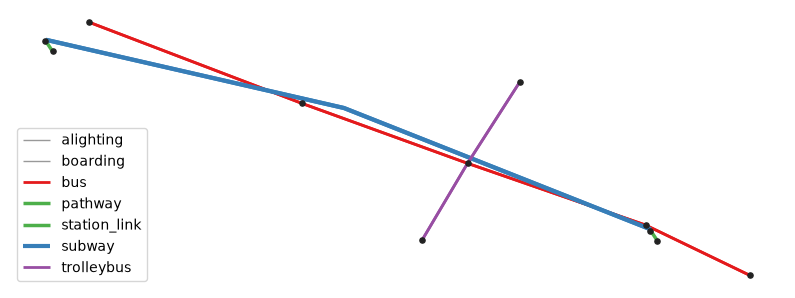

In [14]:
import matplotlib.pyplot as plt

EDGE_STYLE = {
    "subway": ("#377eb8", 3.0),
    "bus": ("#e41a1c", 2.0),
    "trolleybus": ("#984ea3", 2.0),
    "pathway": ("#4daf4a", 2.5),
    "station_link": ("#4daf4a", 2.5),
    "boarding": ("#999999", 1.0),
    "alighting": ("#999999", 1.0),
}

fig, ax = plt.subplots(figsize=(10, 6))
for edge_type, group in edges.groupby("type"):
    color, width = EDGE_STYLE.get(edge_type, ("#bdbdbd", 1.0))
    group.plot(ax=ax, color=color, linewidth=width, label=edge_type)
nodes = public_transport.nodes_gdf
nodes.loc[nodes["type"].isin(["platform", "station_platform", "station_entry_exit"])].plot(
    ax=ax, color="#222222", markersize=14, zorder=3
)
ax.legend(loc="lower left")
ax.set_axis_off()
plt.show()

## Join with the walking network

Build the walking graph first and pass its CRS to the GTFS builder, so both layers share one metric projection. `join_pt_walk_graph` then attaches platforms and station entrances to nearby walking edges.

In [15]:
from iduedu import get_walk_graph, join_pt_walk_graph

walk = get_walk_graph(osm_id=OSM_ID)
public_transport = get_gtfs_public_transport_graph(
    fused, service_date=SERVICE_DATE, start_time="07:00", end_time="10:00", crs=walk.crs
)
intermodal = join_pt_walk_graph(public_transport, walk, max_dist=50)
intermodal

2026-10-22 17:06:07.529 | WARNING  | Removing 326 nodes outside the largest connected component. Retaining 19700 of 20026 nodes.


UrbanGraph(nodes=19739, edges=26593, is_multigraph=True, is_directed=True, edge_direction_column='oneway', crs='EPSG:32636', type='intermodal')

## Route across the layers

Take the walking nodes nearest to a point by Primorskaya and a point on 1-ya Liniya, find the fastest route between them, and turn it into edges to see how the time splits between walking, waiting and riding.

In [16]:
import geopandas as gpd
from shapely.geometry import Point

from iduedu import path_to_edges

points = gpd.GeoSeries([Point(30.2330, 59.9490), Point(30.2860, 59.9410)], crs=4326).to_crs(intermodal.crs)
walk_nodes = intermodal.nodes_gdf.loc[intermodal.nodes_gdf["type"].isna()]
origin, destination = walk_nodes.index[walk_nodes.sindex.nearest(points)[1]]

journey = intermodal.single_source_dijkstra(
    origin, target_nodes=[destination], weight="time_min",
    output="both", path_storage="lazy",
)
path = journey.get_path(destination)
route = path_to_edges(intermodal, path or [])
print(f"travel time: {journey.distances.loc[destination]:.1f} min")
route.groupby("type", sort=False)["time_min"].sum().round(1)

travel time: 21.4 min


type
walk            10.9
pathway          4.5
station_link     0.0
boarding         2.0
subway           4.0
alighting        0.0
Name: time_min, dtype: float64

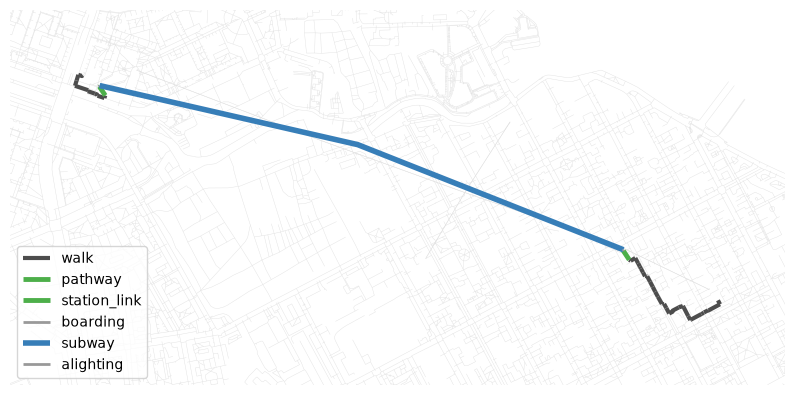

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
intermodal.edges_gdf.plot(ax=ax, color="#e0e0e0", linewidth=0.3)
for edge_type, group in route.groupby("type", sort=False):
    color, width = EDGE_STYLE.get(edge_type, ("#4d4d4d", 2.0))
    group.plot(ax=ax, color=color, linewidth=width + 1, label=edge_type)
xmin, ymin, xmax, ymax = route.total_bounds
ax.set_xlim(xmin - 300, xmax + 300)
ax.set_ylim(ymin - 300, ymax + 300)
ax.legend(loc="lower left")
ax.set_axis_off()
plt.show()